In [2]:
import pandas as pd

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print("Dataset Loaded Successfully!")
print("Total Rows and Columns:", df.shape)

df.head()

Dataset Loaded Successfully!
Total Rows and Columns: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Dataset Shape:
(4340, 8)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [4]:
# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset after cleaning
print("Dataset Shape After Cleaning:", df.shape)

print("Data Cleaning Completed!")

Duplicate Records: 763
Dataset Shape After Cleaning: (3577, 8)
Data Cleaning Completed!


In [5]:
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [7]:
import matplotlib.pyplot as plt
import pandas as pd

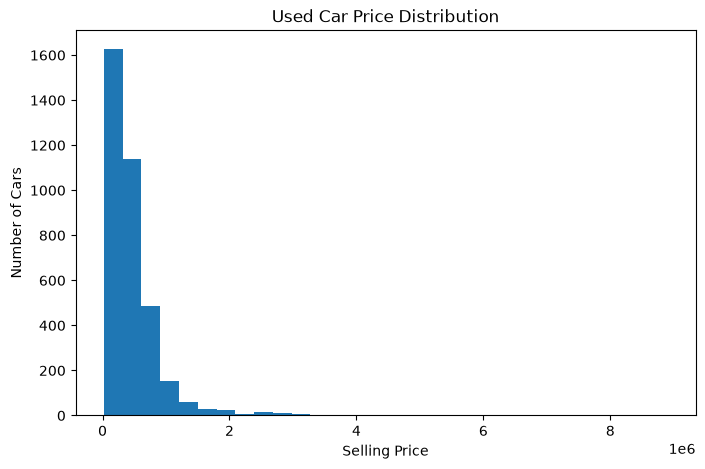

In [8]:
plt.figure(figsize=(8,5))

plt.hist(df["selling_price"], bins=30)

plt.title("Used Car Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

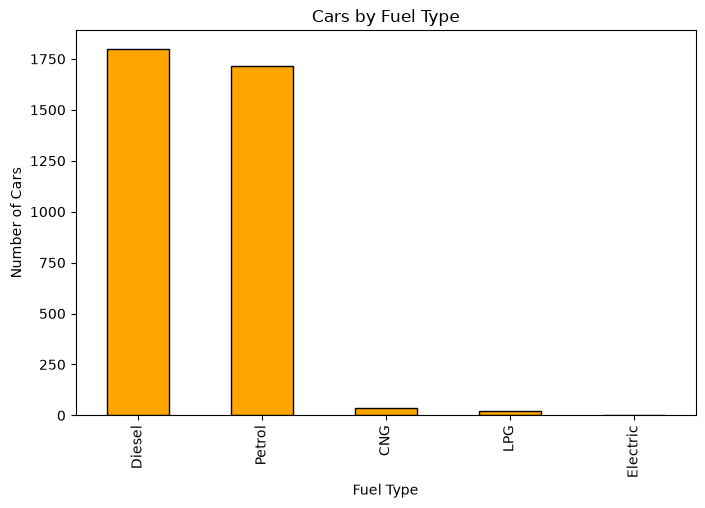

In [9]:
plt.figure(figsize=(8,5))

df["fuel"].value_counts().plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

In [10]:
X = df[
    ["year", "km_driven", "fuel",
     "seller_type", "transmission", "owner"]
]

y = df["selling_price"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nTotal Features:", X.shape[1])

Input Features:
   year  km_driven    fuel seller_type transmission         owner
0  2007      70000  Petrol  Individual       Manual   First Owner
1  2007      50000  Petrol  Individual       Manual   First Owner
2  2012     100000  Diesel  Individual       Manual   First Owner
3  2017      46000  Petrol  Individual       Manual   First Owner
4  2014     141000  Diesel  Individual       Manual  Second Owner

Target Variable:
0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

Total Features: 6


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Train-Test Split Completed!")

Training Data: (2861, 6)
Testing Data: (716, 6)
Train-Test Split Completed!


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Categorical and Numerical Features
categorical_features = [
    "fuel", "seller_type", "transmission", "owner"
]

numerical_features = [
    "year", "km_driven"
]

# Data Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# Create Random Forest Model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train Model
model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [13]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(y_pred[:10])

Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 472990.09498263  659666.46666667 1340660.         2430140.
  104907.73809524  351551.18904762  167864.16666667  913210.95238095
  906850.55267316  228549.99      ]


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 193017.82455881897
R2 Score: 0.4443152103115261


In [15]:
import joblib

model_data = {
    "model": model,
    "mae": mae,
    "r2": r2
}

joblib.dump(model_data, "car_price_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [16]:
saved_model = joblib.load("car_price_model.pkl")

print("Model Loaded Successfully!")
print("MAE:", saved_model["mae"])
print("R2 Score:", saved_model["r2"])

Model Loaded Successfully!
MAE: 193017.82455881897
R2 Score: 0.4443152103115261
